# Laya V3.1 — Layer 15: Local Cellular vs. Long-Range Dilated vs. Fused CeNN

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Laya_V31_Layer15_Cellular_Dilated_Fusion_Colab.ipynb)

**Research question:** Can an attention-free token mixer built from a local cellular branch, a long-range dilated-convolution branch, or both replace **full-attention layer 15** in pretrained \`convaiinnovations/laya-typed-decisions\`?

**Three controlled architectures** share exactly the same pretrained frozen \`W_V\` and \`W_O\` weights and input/output adaptation:

1. \`local_cellular\`: bidirectional cellular recurrence with 5-tap depthwise kernels, **2 recurrent iterations per block**, dilation schedule **[1,2,4,8,16,32]**, theoretical receptive field **505 tokens**.
2. \`long_dilated\`: gated residual 3-tap depthwise convolutions, dilation schedule **[1,2,4,8,16,32,64,128]**, receptive field **511 tokens**.
3. \`cellular_plus_dilated\`: both branches in parallel, token-and-channel-dependent fusion, receptive field **511 tokens**.

**All configurations exceed the requested 256-token minimum receptive field.** Receptive field is the maximum connected input span under these architectures, **not** a promise of reliable gradient transmission or selective retrieval. No Q-K attention/SDPA, FFT, mean pooling or Gaussian memory exists in these replacements.

**Experimental discipline:**
- Mathematical preflight before any training: parameter/shape validation, finite gradients, mask/padding invariance, correctness on CPU-style synthetic tensors on GPU, effective receptive-field formula and pretrained-teacher call replay.
- Frozen teacher, train/probe/audit case-disjoint partitions, deterministic caches (up to 288 different cached training decisions at batch=3), identical successful optimization-update budgets; model choice uses probe metrics only.
- Default **400 successful updates per candidate**; optional longer refinement is disabled. Checkpoint saved **before** evaluation and resumed on rerun.
- Evaluation: probe-only branch-bypass ablation, held-out local-output cosine/NMSE, full decision teacher agreement, gold accuracy drop, Jensen-Shannon divergence, native SDPA vs replacement GPU latency and full-model latency.
- **Thresholds** are hypotheses: cosine ≥0.95, NMSE ≤0.10, teacher agreement ≥0.95, JS ≤0.02 and layer speedup >1.0×.
- Training/test caveat: only task-specific layer-15 distillation. No official test set is accessed. Head-to-head matched within this notebook; earlier V2.9/V3.0 runs used different evaluation samples.

**Limitation:** Dilation enlarges the receptive field but does not create content-addressed remote key retrieval. A failure is informative; increasing dilation or training steps alone is not guaranteed to cure the limitation.

## Padding preflight corrected (October 2026)

A reported BF16/FP16 valid-prefix difference of `0.015625` across sequence lengths 279 and 320 is not, by itself, proof that padded tokens influence valid tokens. Low-precision GEMM/convolution kernels and algorithm selection can change rounding with tensor shapes. Preflight now **fails on masked-content leakage at identical shape**, and independently checks **FP32 prefix invariance with TF32 disabled**. The AMP different-length value is reported for transparency, not used as a brittle fixed absolute threshold. It does **not** silently disable padding checks or change model parameters.


In [1]:
#@title 1. Install exact training dependencies
%pip -q install "transformers==4.57.6" "datasets>=2.20" "huggingface_hub>=0.25,<1" "safetensors>=0.4"
%pip -q install -U "git+https://github.com/vtavakkoli/TinyCeNN-LM.git@main"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 45.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
#@title 2. Imports, frozen Laya teacher and experiment configuration
from pathlib import Path
import copy, json, math, random, time
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer

from tinycenn_lm.decision_v25 import layer_kinds
from tinycenn_lm.laya_lab.core import _valid_tokens
from tinycenn_lm.standalone_decision import (
    QTYPES, build_checkpoint_model, build_sequence,
    collate_items, normalize_question,
)
from tinycenn_lm.decision_training import require_finite

SEED = 2031
SOURCE_MODEL = "convaiinnovations/laya-typed-decisions" #@param {type:"string"}
LAYER = 15 #@param {type:"integer"}
TARGET_LAYERS = (LAYER,)
TRAIN_CASES = 600 #@param {type:"integer"}
DEV_CASES = 200 #@param {type:"integer"}
MAX_LEN = 512 #@param {type:"integer"}
BATCH = 3 #@param {type:"integer"}
STEPS = 400 #@param {type:"integer"}
REFINE_STEPS = 0 #@param {type:"integer"}
REFINE_TOP_K = 1 #@param {type:"integer"}
TRAIN_CACHE_BATCHES = 96 #@param {type:"integer"}
PROBE_CACHE_BATCHES = 16 #@param {type:"integer"}
AUDIT_CACHE_BATCHES = 16 #@param {type:"integer"}
CHECK_EVERY = 100 #@param {type:"integer"}
OUTPUT_DIR = Path("/content/Laya_V31_Layer15_Dilated")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert STEPS >= 1 and DEV_CASES >= 4, "Need at least one successful update and a meaningful held-out split"
assert REFINE_TOP_K >= 1 and TRAIN_CACHE_BATCHES > 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Use a CUDA GPU runtime in Google Colab.")
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda")
amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16

source_dir = Path(snapshot_download(
    SOURCE_MODEL, allow_patterns=[
        "rl_agent_config.json", "model.safetensors", "encoder/*", "tokenizer/*",
    ],
))
teacher, source_cfg = build_checkpoint_model(source_dir)
student_eval, _ = build_checkpoint_model(source_dir)
tokenizer = AutoTokenizer.from_pretrained(str(source_dir / "tokenizer"))
teacher.to(device).eval().requires_grad_(False)
student_eval.to(device).eval().requires_grad_(False)
teacher.encoder.config.reference_compile = False
student_eval.encoder.config.reference_compile = False

kinds = layer_kinds(teacher.encoder)
full_layers = [i for i, kind in enumerate(kinds) if kind == "full_attention"]
assert LAYER in full_layers, (LAYER, full_layers)
print("GPU:", torch.cuda.get_device_name(0), "AMP:", amp_dtype)
print("Source:", SOURCE_MODEL)
print("Target:", LAYER, "all full attention layers:", full_layers)
print("Screen/refine:", STEPS, REFINE_STEPS, "| full-attention replacement modes: 3 | official test used: NO")


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

rl_agent_config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

GPU: Tesla T4 AMP: torch.float16
Source: convaiinnovations/laya-typed-decisions
Target: 15 all full attention layers: [0, 3, 6, 9, 12, 15, 18, 21, 24, 27]
Screen/refine: 400 0 | full-attention replacement modes: 3 | official test used: NO


In [3]:
#@title 3. Leak-free train/dev data and teacher I/O helpers
def _jsonish(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except Exception:
            return x
    return x

def _canon_label(x):
    s = str(x).strip().lower()
    try:
        v = float(s)
        if math.isfinite(v) and v.is_integer():
            return str(int(v))
    except Exception:
        pass
    return s

def _gold_metadata(q, gold_answer):
    if not isinstance(gold_answer, dict):
        raise ValueError("missing gold answer")
    probs_raw = _jsonish(gold_answer.get("probabilities", {}))
    if not isinstance(probs_raw, dict) or len(probs_raw) < 2:
        raise ValueError("gold probabilities missing or malformed")

    gold_keys = [str(k) for k in probs_raw.keys()]
    if q["t"] == "choice":
        labels = [str(k) for k in q["crit"].keys()]
    elif q["t"] == "noul":
        labels = ["false", "true"]
    else:
        labels = list(gold_keys)
        if all(_canon_label(k).lstrip("-").isdigit() for k in labels):
            labels = sorted(labels, key=lambda k: int(_canon_label(k)))

    lookup = {_canon_label(k): float(v) for k, v in probs_raw.items()}
    if len(labels) != len(gold_keys) or any(_canon_label(k) not in lookup for k in labels):
        raise ValueError("Gold labels do not match encoded option order")

    gold_probs = np.asarray([lookup[_canon_label(k)] for k in labels], dtype=np.float64)
    gold_probs = np.clip(gold_probs, 0.0, None)
    if not np.isfinite(gold_probs).all() or gold_probs.sum() <= 0:
        raise ValueError("invalid gold probability vector")
    gold_probs /= gold_probs.sum()

    gold_label = _canon_label(gold_answer.get("label", labels[int(gold_probs.argmax())]))
    canon_labels = [_canon_label(k) for k in labels]
    if gold_label not in canon_labels:
        raise ValueError(f"gold label {gold_label!r} not in {labels!r}")
    return labels, gold_probs.tolist(), canon_labels.index(gold_label)

def make_items_from_rows(rows, seed, shuffle_items):
    out = []
    head_max_len = int(source_cfg.get("head_max_len", 192))
    for row in rows:
        state = _jsonish(row["state"])
        questions = _jsonish(row["questions"])
        gold = _jsonish(row["gold"])
        case_id = str(row.get("id", ""))
        workflow = str(row.get("workflow", "unknown"))
        state_text = state if isinstance(state, str) else json.dumps(state, ensure_ascii=False)
        state_ids = tokenizer(
            state_text.replace(tokenizer.mask_token, " "),
            add_special_tokens=False,
        )["input_ids"]

        for qid, qdef in questions.items():
            q = normalize_question(qdef)
            ids, markers = build_sequence(
                tokenizer,
                state,
                q,
                max_len=min(MAX_LEN, int(source_cfg.get("max_len", MAX_LEN))),
                head_max_len=head_max_len,
                truncate_left=isinstance(state, list),
                state_ids=state_ids,
            )
            if len(markers) < 2:
                continue
            labels, gold_probs, gold_index = _gold_metadata(q, gold[qid])
            if len(labels) != len(markers):
                raise ValueError(
                    f"{case_id}/{qid}: {len(markers)} markers vs {len(labels)} gold labels"
                )
            out.append({
                "ids": ids,
                "markers": markers,
                "qtype": QTYPES[q["t"]],
                "qtype_name": q["t"],
                "qid": str(qid),
                "case_id": case_id,
                "workflow": workflow,
                "labels": labels,
                "gold_probs": gold_probs,
                "gold_index": int(gold_index),
            })
    if shuffle_items:
        random.Random(seed).shuffle(out)
    return out

rows = list(load_dataset("LocalLLaMA/typed-decisions", "all", split="train"))
rng = random.Random(SEED)
rng.shuffle(rows)
assert TRAIN_CASES + DEV_CASES <= len(rows)
train_rows = rows[:TRAIN_CASES]
dev_rows = rows[TRAIN_CASES:TRAIN_CASES + DEV_CASES]
train_items = make_items_from_rows(train_rows, SEED, True)
# Split at the CASE level before creating multiple question items per case.
probe_rows = dev_rows[:len(dev_rows) // 2]
audit_rows = dev_rows[len(dev_rows) // 2:]
probe_items = make_items_from_rows(probe_rows, SEED + 1, True)
audit_items = make_items_from_rows(audit_rows, SEED + 2, True)
dev_items = probe_items # backward-compatible alias for training helper use
assert train_items and probe_items and audit_items
assert {str(r["id"]) for r in probe_rows}.isdisjoint({str(r["id"]) for r in audit_rows})

def direct_batch(selected):
    b = collate_items(selected, int(tokenizer.pad_token_id))
    return {k: v.to(device) for k, v in b.items()}

def batch(items, offset, n=BATCH):
    selected = [items[(offset + i) % len(items)] for i in range(n)]
    return direct_batch(selected)

def _snapshot_attention_argument(value):
    """Retain the exact forward inputs for ModernBERT SDPA replay/timing."""
    if torch.is_tensor(value):
        return value.detach()
    if isinstance(value, tuple):
        return tuple(_snapshot_attention_argument(v) for v in value)
    if isinstance(value, list):
        return [_snapshot_attention_argument(v) for v in value]
    if isinstance(value, dict):
        return {k: _snapshot_attention_argument(v) for k, v in value.items()}
    return value

def _attention_output_tensor(result):
    """ModernBERT variants return either tensor or (tensor, optional weights)."""
    return result[0] if isinstance(result, (tuple, list)) else result

def attn_io(model, layer_idx, b):
    layer = model.encoder.layers[layer_idx]
    got = {}
    def pre(mod, args, kwargs):
        # The encoder passes more than x/position_embeddings/attention_mask:
        # position_ids, sliding_window_mask and optional flags are required by
        # transformers 4.57.6 SDPA. Never infer these for benchmarking.
        got["call_args"] = _snapshot_attention_argument(tuple(args))
        got["call_kwargs"] = _snapshot_attention_argument(dict(kwargs))
        got["x"] = args[0].detach()
        got["pos"] = _snapshot_attention_argument(kwargs.get("position_embeddings"))
        got["mask"] = _snapshot_attention_argument(kwargs.get("attention_mask"))
    def post(mod, args, kwargs, out):
        got["y"] = _attention_output_tensor(out).detach()
    h1 = layer.attn.register_forward_pre_hook(pre, with_kwargs=True)
    h2 = layer.attn.register_forward_hook(post, with_kwargs=True)
    try:
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=amp_dtype):
            model(**b)
    finally:
        h1.remove()
        h2.remove()
    return got

def cache_teacher_io(layer_idx, items, batches, offset=0):
    cache = []
    for i in range(batches):
        b = batch(items, offset + i * BATCH, BATCH)
        got = attn_io(teacher, layer_idx, b)
        cache.append({
            "x": got["x"],
            "pos": got["pos"],
            "mask": got["mask"],
            "call_args": got["call_args"],
            "call_kwargs": got["call_kwargs"],
            "y": got["y"],
            "valid": b["attention_mask"].bool(),
        })
    return cache

def local_metrics_from_cache(repl, cache):
    repl.eval()
    diff_sum = power_sum = cos_sum = 0.0
    tokens = 0
    with torch.no_grad():
        for entry in cache:
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                pred, _ = repl(
                    entry["x"],
                    position_embeddings=entry["pos"],
                    attention_mask=entry["mask"],
                )
            require_finite(pred, "V3.1 local probe")
            valid = entry["valid"]
            m = valid[:, :, None].float()
            d = pred.shape[-1]
            diff_sum += float((((pred.float() - entry["y"].float()) ** 2) * m).sum())
            power_sum += float(((entry["y"].float() ** 2) * m).sum())
            count = int(valid.sum())
            cos_sum += float(
                F.cosine_similarity(
                    pred.float()[valid],
                    entry["y"].float()[valid],
                    dim=-1,
                ).sum()
            )
            tokens += count
    nmse = diff_sum / max(power_sum, 1e-8)
    cosine = cos_sum / max(tokens, 1)
    score = nmse + 1.10 * (1.0 - cosine)
    return {"nmse": nmse, "cosine": cosine, "score": score, "tokens": tokens}

print("train/probe/audit decisions:", len(train_items), len(probe_items), len(audit_items))
print("unique train/probe/audit cases:", len(train_rows), len(probe_rows), len(audit_rows))
assert len(probe_items) >= PROBE_CACHE_BATCHES * BATCH, "Increase DEV_CASES or reduce PROBE_CACHE_BATCHES"
assert len(audit_items) >= AUDIT_CACHE_BATCHES * BATCH, "Increase DEV_CASES or reduce AUDIT_CACHE_BATCHES"
print("official test remains untouched")


README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00001.parquet:   0%|          | 0.00/599k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/222k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

train/probe/audit decisions: 3000 500 500
unique train/probe/audit cases: 600 100 100
official test remains untouched


In [4]:
#@title 4. Three attention-free replacement architectures with ≥256-token receptive field

LOCAL_DILATIONS = (1, 2, 4, 8, 16, 32)
GLOBAL_DILATIONS = (1, 2, 4, 8, 16, 32, 64, 128)
CELL_STEPS = 2
CELL_WIDTH = 256  #@param {type:"integer"}
assert CELL_WIDTH >= 64
assert CELL_STEPS == 2

def predicted_receptive_field(kernel, dilations, repetitions=1):
    # Each convolution grows the receptive-field span by (k-1)*d.
    return 1 + (kernel - 1) * repetitions * sum(dilations)

RF_LOCAL = predicted_receptive_field(5, LOCAL_DILATIONS, CELL_STEPS)
RF_DILATED = predicted_receptive_field(3, GLOBAL_DILATIONS, 1)
assert RF_LOCAL == 505 and RF_DILATED == 511 and min(RF_LOCAL, RF_DILATED) >= 256

class ContractiveCellularStage(nn.Module):
    """Masked CeNN recurrence. Depthwise 5-tap drive + contractive feedback.

    One drive convolution and (steps-1) nonzero feedback convolutions imply
    effective radius <= (5-1)/2 * dilation * steps.
    Feedback kernel L1 norm is <=0.9 per channel. Leak 0<eta<1.
    """
    def __init__(self, channels, dilation, steps=2):
        super().__init__()
        self.dilation, self.steps, self.channels = int(dilation), int(steps), channels
        self.drive = nn.Conv1d(channels, channels, 5,
                               padding=2*dilation, dilation=dilation,
                               groups=channels, bias=False)
        self.feedback = nn.Parameter(torch.zeros(channels, 1, 5))
        self.channel_mix = nn.Conv1d(channels, channels, 1, bias=False)
        self.leak_logit = nn.Parameter(torch.zeros(1, channels, 1))
        self.residual_log_gain = nn.Parameter(torch.tensor(-2.0))
        nn.init.normal_(self.drive.weight, mean=0.0, std=0.02)
        with torch.no_grad():
            self.drive.weight[:,0,2].add_(0.9)
            self.feedback[:,0,2].fill_(0.08)
        nn.init.orthogonal_(self.channel_mix.weight.view(channels, channels))

    def forward(self, x, mask):
        x = x * mask
        drive = self.drive(x) * mask
        weight = self.feedback.tanh()
        weight = 0.9 * weight / weight.abs().sum(-1,keepdim=True).clamp_min(1)
        leak = self.leak_logit.sigmoid()
        state = torch.zeros_like(drive)
        for _ in range(self.steps):
            feedback = F.conv1d(state, weight.to(state.dtype), bias=None,
                                dilation=self.dilation, padding=2*self.dilation,
                                groups=self.channels)
            state = ((1 - leak)*state + leak*torch.tanh(drive + feedback)) * mask
        return (x + self.residual_log_gain.exp()*self.channel_mix(state)) * mask

class GatedDilatedStage(nn.Module):
    """Depthwise 3-tap dilated convolution + pointwise content gate."""
    def __init__(self, channels, dilation):
        super().__init__()
        self.dilation = int(dilation)
        self.dw = nn.Conv1d(channels, channels, 3, padding=dilation,
                            dilation=dilation, groups=channels, bias=False)
        self.mix = nn.Conv1d(channels, channels, 1, bias=False)
        self.gate = nn.Conv1d(channels, channels, 1, bias=True)
        self.residual_log_gain = nn.Parameter(torch.tensor(-2.0))
        nn.init.zeros_(self.dw.weight)
        with torch.no_grad():
            self.dw.weight[:,0,1].fill_(0.90)
            self.dw.weight[:,0,0].fill_(0.02)
            self.dw.weight[:,0,2].fill_(0.02)
        nn.init.zeros_(self.gate.weight)
        nn.init.zeros_(self.gate.bias)

    def forward(self, x, mask):
        x = x * mask
        z = self.dw(x) * mask
        z = F.gelu(self.mix(z))
        g = torch.sigmoid(self.gate(x))
        return (x + self.residual_log_gain.exp() * z * g) * mask

class Layer15CellularDilated(nn.Module):
    """Compatible (tensor, None) replacement, no attention or pooling."""

    def __init__(self, original, mode, width=CELL_WIDTH):
        super().__init__()
        assert mode in ("local_cellular","long_dilated","cellular_plus_dilated")
        self.mode = mode
        self.config = original.config
        d = int(self.config.hidden_size)
        self.hidden_size = d
        self.width = int(width)
        # Freeze value projection and preserve output head of the teacher.
        self.Wv = nn.Linear(d,d,bias=original.Wqkv.bias is not None)
        self.Wo = copy.deepcopy(original.Wo).requires_grad_(False)
        with torch.no_grad():
            self.Wv.weight.copy_(original.Wqkv.weight[2*d:3*d])
            if self.Wv.bias is not None:
                self.Wv.bias.copy_(original.Wqkv.bias[2*d:3*d])
        self.Wv.requires_grad_(False)
        self.input_norm = nn.LayerNorm(d)
        self.down = nn.Linear(d,width,bias=False)
        self.up = nn.Linear(width,d,bias=False)
        self.anchor_logit = nn.Parameter(torch.tensor(0.0))
        self.skip_scale = nn.Parameter(torch.tensor(0.0))
        self.disable_branches = False  # controlled ablation: bypass both token mixers
        self.local = None
        self.long_branch = None
        if mode in ("local_cellular","cellular_plus_dilated"):
            self.local = nn.ModuleList([
                ContractiveCellularStage(width,dilation=s,steps=CELL_STEPS)
                for s in LOCAL_DILATIONS
            ])
        if mode in ("long_dilated","cellular_plus_dilated"):
            self.long_branch = nn.ModuleList([
                GatedDilatedStage(width,dilation=s) for s in GLOBAL_DILATIONS
            ])
        if mode=="cellular_plus_dilated":
            self.fusion = nn.Conv1d(width*3,width,1)
            # Force genuinely learnable per-token per-channel selection.
            nn.init.zeros_(self.fusion.weight)
            nn.init.zeros_(self.fusion.bias)
        else:
            self.fusion = None

    @property
    def receptive_field(self):
        if self.mode=="local_cellular": return RF_LOCAL
        if self.mode=="long_dilated": return RF_DILATED
        return max(RF_LOCAL,RF_DILATED)

    def forward(self, hidden_states, attention_mask=None,
                position_embeddings=None, **kwargs):
        valid = _valid_tokens(attention_mask, hidden_states)
        mask = valid[:,None,:].to(hidden_states.dtype)
        v = self.Wv(hidden_states) * valid[:,:,None].to(hidden_states.dtype)
        u = self.down(self.input_norm(v)).transpose(1,2) * mask
        local = u
        long = u
        if self.local is not None:
            for stage in self.local: local = stage(local,mask)
        if self.long_branch is not None:
            for stage in self.long_branch: long = stage(long,mask)
        if self.fusion is not None:
            gate = torch.sigmoid(self.fusion(torch.cat((u,local,long),dim=1)))
            mixed = (gate*local + (1-gate)*long) * mask
        elif self.local is not None:
            mixed = local
        else:
            mixed = long
        if self.disable_branches:
            mixed = u
        z = self.up(mixed.transpose(1,2))
        # Pretrained value-only anchor helps optimization but cannot recover
        # arbitrary global Q-K retrieval. All modes share this same anchor.
        alpha = torch.sigmoid(self.anchor_logit)
        core = alpha*v + (1-alpha)*z + self.skip_scale*hidden_states
        out = self.Wo(core)
        return out * valid[:,:,None].to(out.dtype), None

    def config_dict(self):
        return dict(architecture="layer15_cellular_dilated_v31",
                    mode=self.mode,width=self.width,
                    local_dilations=list(LOCAL_DILATIONS) if self.local is not None else [],
                    long_dilations=list(GLOBAL_DILATIONS) if self.long_branch is not None else [],
                    cell_iterations=CELL_STEPS if self.local is not None else 0,
                    receptive_field=self.receptive_field,
                    attention_free=True,case_specific_teacher_distillation=True)

CANDIDATE_NAMES = ("local_cellular","long_dilated","cellular_plus_dilated")
CANDIDATE_INFO = {name:dict(label=name.replace("_"," ").title(),
                            lr_start=0.002,lr_end=0.00015)
                  for name in CANDIDATE_NAMES}

def build_candidate(name,original):
    return Layer15CellularDilated(original,mode=name).to(device)

def candidate_parameters(module):
    return [p for p in module.parameters() if p.requires_grad]

for name in CANDIDATE_NAMES:
    sample_model=build_candidate(name,teacher.encoder.layers[LAYER].attn)
    print(f"{name:<24} RF={sample_model.receptive_field:>3} "
          f"trainable_params={sum(p.numel() for p in candidate_parameters(sample_model)):,}")
    del sample_model
torch.cuda.empty_cache()


local_cellular           RF=505 trainable_params=936,456
long_dilated             RF=511 trainable_params=1,583,114
cellular_plus_dilated    RF=511 trainable_params=2,190,096


In [5]:
#@title 5. Mathematical + runtime preflight BEFORE training
# These checks do not claim high fidelity. They check the model is
# mathematically coherent and compatible with the pretrained target.
torch.manual_seed(SEED)
sample = attn_io(teacher,LAYER,batch(probe_items,0,BATCH))
native = teacher.encoder.layers[LAYER].attn
# Exact native replay (SDPA requires full captured kwargs).
with torch.inference_mode(),torch.autocast(device_type="cuda",dtype=amp_dtype):
    replay = _attention_output_tensor(native(*sample["call_args"],**sample["call_kwargs"]))
delta = float((replay.float()-sample["y"].float()).abs().max())
if not torch.allclose(replay.float(),sample["y"].float(),atol=1e-2,rtol=1e-2):
    raise RuntimeError(f"Frozen teacher replay failed: maximum error {delta}")
print(f"Native SDPA replay: PASS | max abs diff={delta:.6g}")
del replay

def pad_invariance(model, length=279, padded=320):
    """Separate mathematical padding leaks from BF16/FP16 kernel-rounding drift.

    1) Same-length masked-noise vs masked-zero: detects real padded-token leaks.
       The tensor shapes and low-precision kernels are IDENTICAL.
    2) Different-length FP32 prefix comparison with TF32 disabled: tests
       zero-padding invariance without BF16/FP16 shape-dependent rounding.
    3) Different-length AMP prefix: report only; different cuDNN algorithms
       and quantization may cause nonzero drift such as 0.015625 in BF16.
    """
    g = torch.Generator(device=device).manual_seed(3290)
    dim = model.hidden_size
    x = torch.randn(1, length, dim, device=device, generator=g, dtype=torch.float32)
    noise = torch.randn(1, padded-length, dim, device=device,
                        generator=g, dtype=torch.float32)*2.0
    z_noise = torch.cat([x,noise], dim=1)
    z_zero = torch.cat([x,torch.zeros_like(noise)], dim=1)
    ma = torch.ones(1,length,device=device,dtype=torch.long)
    mb = torch.cat([ma,torch.zeros(1,padded-length,device=device,dtype=torch.long)],dim=1)
    model.eval()
    old_matmul_tf32 = torch.backends.cuda.matmul.allow_tf32
    try:
        torch.backends.cuda.matmul.allow_tf32 = False
        with torch.no_grad():
            # Keep FP32 and disable TF32 approximations for the strict structural test.
            with torch.backends.cudnn.flags(benchmark=False,deterministic=True,
                                           allow_tf32=False):
                with torch.autocast(device_type="cuda",enabled=False):
                    fp_short = model(x,attention_mask=ma)[0].float()
                    fp_long = model(z_noise,attention_mask=mb)[0][:,:length].float()
            with torch.autocast(device_type="cuda",dtype=amp_dtype):
                amp_short = model(x,attention_mask=ma)[0].float()
                amp_long = model(z_noise,attention_mask=mb)[0][:,:length].float()
                amp_zero = model(z_zero,attention_mask=mb)[0][:,:length].float()
    finally:
        torch.backends.cuda.matmul.allow_tf32 = old_matmul_tf32

    fp_diff = fp_short - fp_long
    content_diff = amp_long - amp_zero
    amp_diff = amp_short - amp_long
    scale = fp_short.square().mean().sqrt().clamp_min(1e-4)
    return {
        "fp32_max_abs": float(fp_diff.abs().amax()),
        "fp32_relative_rmse": float(fp_diff.square().mean().sqrt()/scale),
        "amp_padded_content_max_abs": float(content_diff.abs().amax()),
        "amp_length_max_abs": float(amp_diff.abs().amax()),
        "amp_dtype": str(amp_dtype),
    }

for name in CANDIDATE_NAMES:
    model=build_candidate(name,native)
    model.train()
    with torch.autocast(device_type="cuda",dtype=amp_dtype):
        output,_=model(sample["x"],attention_mask=sample["mask"],
                       position_embeddings=sample["pos"])
        valid=batch(probe_items,0,BATCH)["attention_mask"].bool()
        err=(output.float()[valid]-sample["y"].float()[valid])
        loss=err.square().mean()
    require_finite(output,name+" outputs")
    require_finite(loss,name+" loss")
    grad=torch.autograd.grad(loss,candidate_parameters(model),allow_unused=True)
    active=[float(g.abs().sum()) for g in grad if g is not None]
    if not active or not np.isfinite(sum(active)) or sum(active)==0:
        raise RuntimeError(name+": no finite nonzero gradients")
    invariance=pad_invariance(model)
    # Same-length padded content must have no effect; check even with AMP.
    # FP32 prefix check rules out a genuine boundary/padding defect.
    if invariance["amp_padded_content_max_abs"] > 1e-4:
        raise RuntimeError(
            f"{name}: padding contents leaked into valid tokens: {invariance}"
        )
    if (invariance["fp32_max_abs"] > 1e-3
            and invariance["fp32_relative_rmse"] > 1e-4):
        raise RuntimeError(
            f"{name}: structural FP32 padding invariance failed: {invariance}"
        )
    print(f"{name:<24} PASS | loss={float(loss):.6f} | grads={len(active)} "
          f"| FP32 padding Δmax={invariance['fp32_max_abs']:.3g} "
          f"| AMP masked-noise Δmax={invariance['amp_padded_content_max_abs']:.3g} "
          f"| AMP length-only Δmax={invariance['amp_length_max_abs']:.5g} "
          f"| RF={model.receptive_field}")
    if invariance["amp_length_max_abs"] > 0.01:
        print(f"  NOTE {name}: low-precision length-dependent kernel rounding "
              f"({invariance['amp_dtype']}); FP32/identical-shape masking checks passed.")
    del model,output,loss,grad
torch.cuda.empty_cache()
print("All three candidates passed the preflight; training may proceed.")


Native SDPA replay: PASS | max abs diff=0


/tmp/ipykernel_829/3107257618.py:92: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print(f"{name:<24} PASS | loss={float(loss):.6f} | grads={len(active)} "


local_cellular           PASS | loss=1.823492 | grads=36 | FP32 padding Δmax=3.81e-06 | AMP masked-noise Δmax=0 | AMP length-only Δmax=0.015625 | RF=505
  NOTE local_cellular: low-precision length-dependent kernel rounding (torch.float16); FP32/identical-shape masking checks passed.
long_dilated             PASS | loss=1.813582 | grads=46 | FP32 padding Δmax=3.81e-06 | AMP masked-noise Δmax=0 | AMP length-only Δmax=0.015625 | RF=511
  NOTE long_dilated: low-precision length-dependent kernel rounding (torch.float16); FP32/identical-shape masking checks passed.
cellular_plus_dilated    PASS | loss=1.812675 | grads=78 | FP32 padding Δmax=3.81e-06 | AMP masked-noise Δmax=0 | AMP length-only Δmax=0.015625 | RF=511
  NOTE cellular_plus_dilated: low-precision length-dependent kernel rounding (torch.float16); FP32/identical-shape masking checks passed.
All three candidates passed the preflight; training may proceed.


In [6]:
#@title 6. Equal-budget layer-15 teacher distillation, checkpoint best PROBE only
def state_cpu(module):
    return {k:v.detach().cpu().clone() for k,v in module.state_dict().items()}

def ranking_score(metrics):
    return metrics["nmse"]+1.10*(1.0-metrics["cosine"])

def cosine_lr(update,total,start,end):
    frac=min(update/max(total-1,1),1.)
    return end + 0.5*(start-end)*(1+math.cos(math.pi*frac))

def fit_local(name,model,training_cache,probe_cache,steps):
    params=candidate_parameters(model)
    conf=CANDIDATE_INFO[name]
    opt=torch.optim.AdamW(params,lr=conf["lr_start"],betas=(0.9,0.95),
                          weight_decay=1e-4)
    scaler=torch.amp.GradScaler("cuda",enabled=amp_dtype==torch.float16)
    best=local_metrics_from_cache(model,probe_cache)
    best_score=ranking_score(best)
    best_state=state_cpu(model)
    best_step=0
    history=[{"step":0,**best}]
    updates=attempts=0
    print(f"{name} initial: cos={best['cosine']:.5f} NMSE={best['nmse']:.5f}")
    while updates<steps:
        if attempts>steps+500: raise RuntimeError("Excessive nonfinite optimizer steps")
        entry=training_cache[attempts%len(training_cache)]
        lr=cosine_lr(updates,steps,conf["lr_start"],conf["lr_end"])
        for group in opt.param_groups: group["lr"]=lr
        model.train()
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda",dtype=amp_dtype):
            pred,_=model(entry["x"],attention_mask=entry["mask"],
                         position_embeddings=entry["pos"])
            valid=entry["valid"]
            p=pred.float()[valid]
            y=entry["y"].float()[valid]
            nmse=(p-y).square().sum()/y.square().sum().clamp_min(1e-8)
            cos=F.cosine_similarity(p,y,dim=-1).mean()
            loss=nmse+1.1*(1.0-cos)
        require_finite(loss,name+" loss")
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(params,1.0)
        scale_before=scaler.get_scale()
        scaler.step(opt)
        scaler.update()
        attempts+=1
        if scaler.is_enabled() and scaler.get_scale()<scale_before:
            continue
        updates+=1
        if updates==1 or updates%CHECK_EVERY==0 or updates==steps:
            model.eval()
            quality=local_metrics_from_cache(model,probe_cache)
            history.append({"step":updates,**quality})
            if ranking_score(quality)<best_score:
                best,best_score,best_step=quality,ranking_score(quality),updates
                best_state=state_cpu(model)
            print(f"  {updates:04d}/{steps}: probe cos={quality['cosine']:.4f} "
                  f"NMSE={quality['nmse']:.4f} | selected cosine={best['cosine']:.4f} @{best_step}")
    model.load_state_dict(best_state,strict=True)
    model.eval()
    return dict(updates=updates,attempts=attempts,steps=steps,
                best_step=best_step,probe=best,history=history)


In [7]:
#@title 7. E2E teacher agreement and GPU latency of actual modules
@torch.no_grad()
def validate_pair(student, items, limit=None):
    teacher.eval()
    student.eval()
    limit = len(items) if limit is None else min(int(limit), len(items))
    n = matched = teacher_gold = student_gold = 0
    jensen = []
    for offset in range(0, limit, BATCH):
        chosen = items[offset:min(offset+BATCH, limit)]
        b = direct_batch(chosen)
        with torch.autocast(device_type="cuda", dtype=amp_dtype):
            tl, _ = teacher(**b)
            sl, _ = student(**b)
        require_finite(tl, "teacher logits")
        require_finite(sl, "student logits")
        mask = b["marker_mask"].bool()
        tp = torch.softmax(tl.float().masked_fill(~mask, -1e9), dim=-1)
        sp = torch.softmax(sl.float().masked_fill(~mask, -1e9), dim=-1)
        gold = torch.tensor([c["gold_index"] for c in chosen], device=device)
        n += len(chosen)
        matched += int((tp.argmax(-1) == sp.argmax(-1)).sum())
        teacher_gold += int((tp.argmax(-1) == gold).sum())
        student_gold += int((sp.argmax(-1) == gold).sum())
        mid = .5*(tp+sp)
        j = .5*((tp*(tp.clamp_min(1e-8).log()-mid.clamp_min(1e-8).log())).sum(-1))
        j += .5*((sp*(sp.clamp_min(1e-8).log()-mid.clamp_min(1e-8).log())).sum(-1))
        jensen.extend(j.cpu().tolist())
    return dict(decisions=n, agreement=matched/max(n,1), mean_js=float(np.mean(jensen)),
                teacher_gold_accuracy=teacher_gold/max(n,1),
                student_gold_accuracy=student_gold/max(n,1),
                gold_accuracy_drop=(teacher_gold-student_gold)/max(n,1))

@torch.inference_mode()
def time_module(module, entry, *, native_teacher=False, warmup=5, repeats=20):
    """Measure native SDPA with its captured encoder call, or a CeNN replacement.

    ModernBERT SDPA requires position_ids and sliding_window_mask even when
    only full attention is being benchmarked. Replaying the original call is
    safer than synthesizing masks and prevents the missing-kwargs TypeError.
    """
    module.eval()
    if native_teacher:
        if "call_args" not in entry or "call_kwargs" not in entry:
            raise RuntimeError(
                "Teacher I/O cache predates SDPA signature fix. Rerun cell 3 "
                "and rebuild cache in cell 8 (or recapture with attn_io)."
            )
        args, kwargs = entry["call_args"], entry["call_kwargs"]
    else:
        args = (entry["x"],)
        kwargs = dict(position_embeddings=entry["pos"], attention_mask=entry["mask"])

    def invoke():
        return _attention_output_tensor(module(*args, **kwargs))

    with torch.autocast(device_type="cuda", dtype=amp_dtype):
        for _ in range(warmup):
            last = invoke()
        require_finite(last, "timing warmup output")
        torch.cuda.synchronize()
        times = []
        for _ in range(repeats):
            start = time.perf_counter()
            invoke()
            torch.cuda.synchronize()
            times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

@torch.inference_mode()
def time_model(model, chosen, warmup=3, repeats=10):
    b = direct_batch(chosen)
    model.eval()
    with torch.autocast(device_type="cuda", dtype=amp_dtype):
        for _ in range(warmup): model(**b)
        torch.cuda.synchronize()
        times=[]
        for _ in range(repeats):
            start=time.perf_counter()
            model(**b)
            torch.cuda.synchronize()
            times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def length_diagnostics(items):
    lengths=np.array([len(it["ids"]) for it in items], dtype=np.int64)
    return dict(items=len(items), median_tokens=float(np.median(lengths)),
                p90_tokens=float(np.percentile(lengths,90)),
                max_tokens=int(lengths.max()),
                count_ge_256=int((lengths >= 256).sum()),
                count_ge_512=int((lengths >= 512).sum()))

@torch.no_grad()
def evaluate_candidate(layer_idx, replacement, audit_cache, items=audit_items):
    original = student_eval.encoder.layers[layer_idx].attn
    student_eval.encoder.layers[layer_idx].attn = replacement
    try:
        replacement.eval()
        local=local_metrics_from_cache(replacement, audit_cache)
        downstream=validate_pair(student_eval, items)
        entry=audit_cache[0]
        teacher_ms=time_module(teacher.encoder.layers[layer_idx].attn, entry, native_teacher=True)
        student_ms=time_module(replacement, entry, native_teacher=False)
        fixed=items[:min(BATCH,len(items))]
        teacher_total=time_model(teacher, fixed)
        student_total=time_model(student_eval, fixed)
        return dict(local=local, e2e=downstream, attention_ms=student_ms,
                    teacher_attention_ms=teacher_ms,
                    attention_speedup=teacher_ms/max(student_ms,1e-8),
                    model_ms=student_total, teacher_model_ms=teacher_total,
                    model_speedup=teacher_total/max(student_total,1e-8))
    finally:
        student_eval.encoder.layers[layer_idx].attn = original
        student_eval.eval().requires_grad_(False)

def gate(e):
    local=e["local"]
    downstream=e["e2e"]
    return bool(local["cosine"] >= .95 and local["nmse"] <= .10
                and downstream["agreement"] >= .95
                and downstream["mean_js"] <= .02
                and e["attention_speedup"] > 1.0)

print("Probe length profile:", length_diagnostics(probe_items))
print("Audit length profile:", length_diagnostics(audit_items))
print("Teacher baseline:", validate_pair(student_eval, audit_items))


Probe length profile: {'items': 500, 'median_tokens': 312.5, 'p90_tokens': 414.20000000000005, 'max_tokens': 512, 'count_ge_256': 327, 'count_ge_512': 15}
Audit length profile: {'items': 500, 'median_tokens': 306.0, 'p90_tokens': 376.0, 'max_tokens': 512, 'count_ge_256': 343, 'count_ge_512': 1}
Teacher baseline: {'decisions': 500, 'agreement': 1.0, 'mean_js': 0.0, 'teacher_gold_accuracy': 0.864, 'student_gold_accuracy': 0.864, 'gold_accuracy_drop': 0.0}


In [8]:
#@title 8. Run the 3-way layer-15 tournament with safe checkpoint/resume
# Cache teacher tensors once. This samples 96*3=288 distinct training
# decisions before repetition, doubling the original V2.9 cache coverage.
train_cache=cache_teacher_io(LAYER,train_items,TRAIN_CACHE_BATCHES,offset=7)
probe_cache=cache_teacher_io(LAYER,probe_items,PROBE_CACHE_BATCHES,offset=0)
audit_cache=cache_teacher_io(LAYER,audit_items,AUDIT_CACHE_BATCHES,offset=0)
print("Teacher cache sizes: train",len(train_cache)*BATCH,
      "probe",len(probe_cache)*BATCH,"audit",len(audit_cache)*BATCH)
results=[]
for i,name in enumerate(CANDIDATE_NAMES):
    random.seed(SEED+101*i)
    np.random.seed(SEED+101*i)
    torch.manual_seed(SEED+101*i)
    torch.cuda.manual_seed_all(SEED+101*i)
    print("\n"+"="*90)
    print(f"LAYER 15 V3.1 — {name.upper()} | RF >=256")
    print("="*90)
    model=build_candidate(name,teacher.encoder.layers[LAYER].attn)
    checkpoint_path=OUTPUT_DIR/f"layer15_{name}_screen.pt"
    if checkpoint_path.exists():
        saved=torch.load(checkpoint_path,map_location="cpu",weights_only=False)
        if saved.get("name")!=name or saved.get("layer")!=LAYER or saved.get("steps")!=STEPS:
            raise RuntimeError(f"Existing checkpoint incompatible with current experiment: {checkpoint_path}")
        model.load_state_dict(saved["state_dict"],strict=True)
        trained=saved["train"]
        print("RESUME FROM COMPLETED SCREEN:",checkpoint_path)
    else:
        trained=fit_local(name,model,train_cache,probe_cache,STEPS)
        # Preserve trained work BEFORE any e2e/latency evaluation errors.
        torch.save(dict(version="3.1",name=name,layer=LAYER,steps=STEPS,
                        width=CELL_WIDTH,config=model.config_dict(),
                        state_dict=state_cpu(model),train=trained),checkpoint_path)
        print("Saved candidate before evaluation:",checkpoint_path)
    # Probe-only ablation: does the learned convolution actually help beyond
    # the common pretrained-V anchor and pointwise adapter?
    model.eval()
    model.disable_branches=True
    try:
        bypass_probe=local_metrics_from_cache(model,probe_cache)
    finally:
        model.disable_branches=False
    print(f"ABLATION {name}: mixed probe cosine={trained['probe']['cosine']:.4f} "
          f"vs bypassed={bypass_probe['cosine']:.4f}")
    audit=evaluate_candidate(LAYER,model,audit_cache)
    item=dict(name=name,train=trained,audit=audit,checkpoint=str(checkpoint_path),
              bypass_probe=bypass_probe,
              score=ranking_score(trained["probe"]),passes_gates=gate(audit),
              trainable_parameters=sum(p.numel() for p in candidate_parameters(model)),
              receptive_field=model.receptive_field)
    results.append(item)
    print(f"RESULT {name} probe={trained['probe']['cosine']:.4f} "
          f"audit_cos={audit['local']['cosine']:.4f} nmse={audit['local']['nmse']:.4f} "
          f"agreement={audit['e2e']['agreement']:.4f} "
          f"accuracy_drop={audit['e2e']['gold_accuracy_drop']:+.3f} "
          f"layer_speedup={audit['attention_speedup']:.3f}x")
    del model
    torch.cuda.empty_cache()
# Winner is chosen from probe only; audit never affects selection.
ranked=sorted(results,key=lambda r:(r["score"],-r["train"]["probe"]["cosine"]))
winner=ranked[0]
print("\nPROBE-SELECTED WINNER:",winner["name"])
print("Selected audit:",json.dumps(winner["audit"],indent=2))


Teacher cache sizes: train 288 probe 48 audit 48

LAYER 15 V3.1 — LOCAL_CELLULAR | RF >=256
local_cellular initial: cos=0.29396 NMSE=1.39684
  0001/400: probe cos=0.3795 NMSE=1.2833 | selected cosine=0.3795 @1
  0100/400: probe cos=0.6788 NMSE=0.5842 | selected cosine=0.6788 @100
  0200/400: probe cos=0.7121 NMSE=0.5166 | selected cosine=0.7121 @200
  0300/400: probe cos=0.7294 NMSE=0.4874 | selected cosine=0.7294 @300
  0400/400: probe cos=0.7353 NMSE=0.4767 | selected cosine=0.7353 @400
Saved candidate before evaluation: /content/Laya_V31_Layer15_Dilated/layer15_local_cellular_screen.pt
ABLATION local_cellular: mixed probe cosine=0.7353 vs bypassed=0.7082
RESULT local_cellular probe=0.7353 audit_cos=0.7514 nmse=0.4471 agreement=0.7660 accuracy_drop=+0.166 layer_speedup=0.328x

LAYER 15 V3.1 — LONG_DILATED | RF >=256
long_dilated initial: cos=0.29270 NMSE=1.37981
  0001/400: probe cos=0.3877 NMSE=1.2804 | selected cosine=0.3877 @1
  0100/400: probe cos=0.6896 NMSE=0.5658 | selected co

Saved: /content/Laya_V31_Layer15_Dilated/v31_cellular_vs_dilated_vs_fused.json

MATCHED HOLDOUT COMPARISON
method                      probe_cos  audit_cos     NMSE  agreement  layer_x
local_cellular                 0.7353     0.7514   0.4471     0.7660    0.328
long_dilated                   0.7610     0.7786   0.3992     0.7940    0.387
cellular_plus_dilated          0.7646     0.7823   0.3925     0.7940    0.180


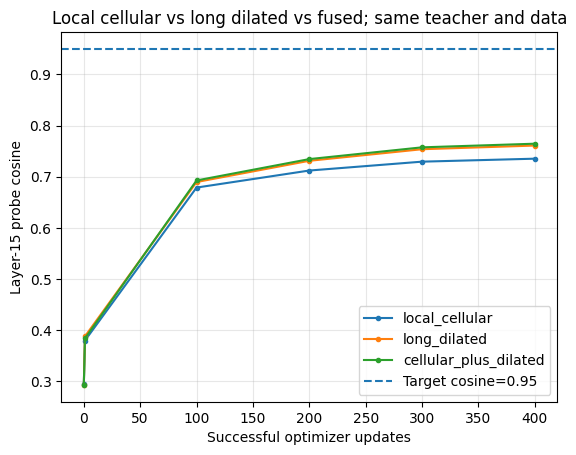

Verdict: NOT READY to replace pretrained attention in production
Files remain in Colab runtime. Copy OUTPUT_DIR to Google Drive to persist checkpoints.


In [9]:
#@title 9. Full report, ablation comparison and plots
if not results: raise RuntimeError("Run cell 8 before summary")
report=dict(version="3.1",layer=LAYER,model=SOURCE_MODEL,
            teacher_frozen=True,official_test_used=False,
            train_cases=len(train_rows),probe_cases=len(probe_rows),
            audit_cases=len(audit_rows),
            training_cache_decisions=len(train_cache)*BATCH,
            training_steps=STEPS,
            local_receptive_field=RF_LOCAL,
            dilated_receptive_field=RF_DILATED,
            winner_by_probe=winner["name"],
            winner_checkpoint=winner["checkpoint"],
            candidate_metrics=results,
            selection_rule="lowest probe NMSE+1.1*(1-cosine); audit not used",
            warnings=[
                "This is a layer-15 task-specific attention-replacement experiment.",
                "Dilated convolutions offer wide receptive fields, not arbitrary content-addressed retrieval.",
                "Theoretical receptive field does not guarantee strong effective long-range gradients.",
                "Latency must be measured on identical hardware and representative lengths.",
                "The source dataset official test split has not been used.",
            ])
report_path=OUTPUT_DIR/"v31_cellular_vs_dilated_vs_fused.json"
report_path.write_text(json.dumps(report,indent=2,allow_nan=False),encoding="utf-8")
print("Saved:",report_path)
print("\nMATCHED HOLDOUT COMPARISON")
print(f"{'method':<26} {'probe_cos':>10} {'audit_cos':>10} {'NMSE':>8} {'agreement':>10} {'layer_x':>8}")
for r in results:
    a=r["audit"]
    print(f"{r['name']:<26} {r['train']['probe']['cosine']:10.4f} "
          f"{a['local']['cosine']:10.4f} {a['local']['nmse']:8.4f} "
          f"{a['e2e']['agreement']:10.4f} {a['attention_speedup']:8.3f}")
import matplotlib.pyplot as plt
for r in results:
    hist=r["train"]["history"]
    plt.plot([x["step"] for x in hist],
             [x["cosine"] for x in hist],marker=".",label=r["name"])
plt.axhline(.95,linestyle="--",label="Target cosine=0.95")
plt.xlabel("Successful optimizer updates")
plt.ylabel("Layer-15 probe cosine")
plt.title("Local cellular vs long dilated vs fused; same teacher and data")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print("Verdict:", "PROMISING, needs replication" if winner["passes_gates"]
      else "NOT READY to replace pretrained attention in production")
print("Files remain in Colab runtime. Copy OUTPUT_DIR to Google Drive to persist checkpoints.")
